# 02 · Synthetic households

Each household is drawn from **continuous latent traits** (privacy concern, trust in the maker, aversion to
third parties and to inference, retention sensitivity, how much it values features, children). Its decision on
each of the 6,272 items follows from those traits; its answers to the candidate questions follow from the same
traits plus noise. Every number is in `config/generator.yaml` with the study its direction comes from.

Decisions: **deny**, **allow**, or **allow if limited** with the limit (not kept, in-home only, on-device only).
There is no "ask me" decision: PPD effects are allow and deny.

> Not survey data. It shows the pipeline works and which questions matter *under these assumptions*.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ppd_presets.items import build_items, load_corpus
from ppd_presets.generate import load_config, generate, ORDINAL, DECISION_CODES, TRAITS
from ppd_presets.questions import answer, question_bank
from ppd_presets import dataset
from ppd_presets.taxonomy import short

cfg = load_config(ROOT / "config/generator.yaml")
items = build_items(load_corpus(ROOT / "data/corpus/flows.csv"))
synth = generate(cfg, items)
answers = answer(synth.households, cfg, np.random.default_rng(cfg["seed"] + 1))
H, D = synth.households, synth.decisions
print(f"{len(H):,} households x {D.shape[1]:,} items = {D.size:,} decisions")

5,000 households x 6,272 items = 31,360,000 decisions


## Decisions overall

In [2]:
shares = pd.Series({DECISION_CODES[k]: (D == k).mean() for k in DECISION_CODES}, name="share")
shares.map("{:.1%}".format)

deny                                             28.0%
allow                                            53.9%
allow_if:retention=ppd:ephemeral                  7.4%
allow_if:processing_boundary=ppd:inHomeOnly       7.7%
allow_if:processing_boundary=ppd:onDeviceOnly     3.0%
Name: share, dtype: str

## Do the effects point the way the studies say?

Mean acceptance (deny 0, allow-if-limited 0.5, allow 1) by each field. Expected from the literature: content/video
and location least accepted (N17), advertising and analytics least accepted purposes, third parties and public
lower than the vendor, everything far higher when the data stays home, inference and transfer lower (N17, N21).

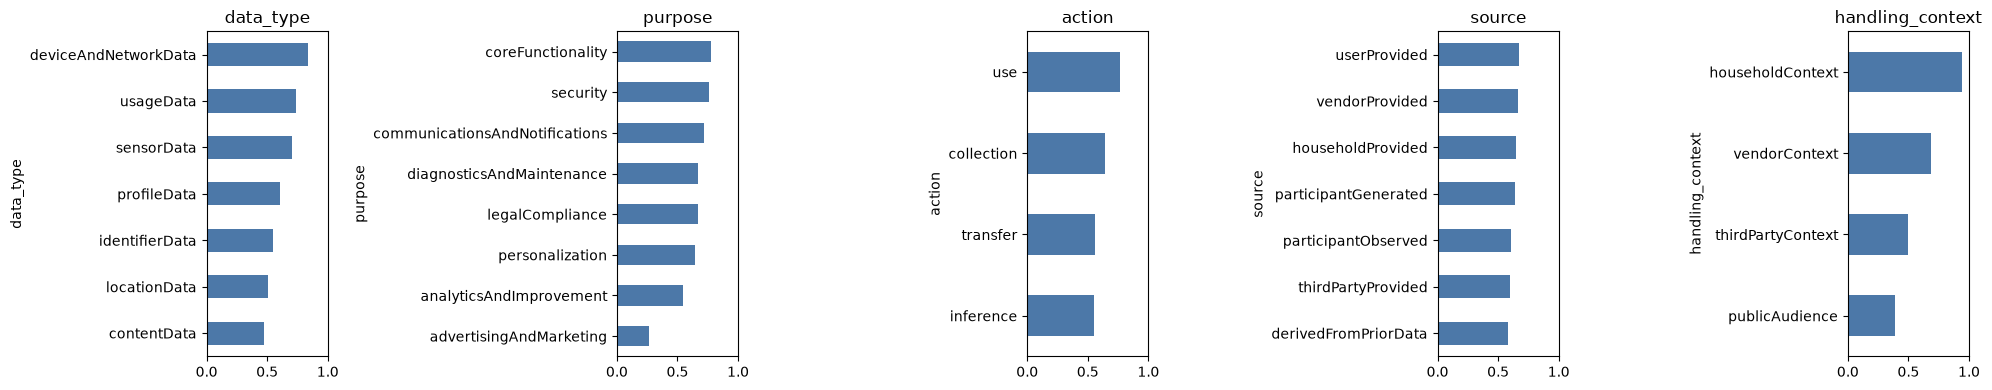

In [3]:
V = ORDINAL[D]
item_mean = pd.Series(V.mean(axis=0))
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, ["data_type", "purpose", "action", "source", "handling_context"]):
    m = item_mean.groupby(items[f].map(short)).mean().sort_values()
    m.plot.barh(ax=ax, color="#4c78a8"); ax.set_xlim(0, 1); ax.set_title(f)
plt.tight_layout(); plt.show()

In [4]:
checks = {
    "content least accepted data type": item_mean.groupby(items.data_type).mean().idxmin() == "ppd:contentData",
    "advertising least accepted purpose": item_mean.groupby(items.purpose).mean().idxmin() == "ppd:advertisingAndMarketing",
    "household context most accepted": item_mean.groupby(items.handling_context).mean().idxmax() == "ppd:householdContext",
    "third party below vendor": item_mean[items.handling_context == "ppd:thirdPartyContext"].mean() < item_mean[items.handling_context == "ppd:vendorContext"].mean(),
    "inference below use": item_mean[items.action == "ppd:inference"].mean() < item_mean[items.action == "ppd:use"].mean(),
}
pd.Series(checks, name="holds")

content least accepted data type      True
advertising least accepted purpose    True
household context most accepted       True
third party below vendor              True
inference below use                   True
Name: holds, dtype: bool

## Households differ

How permissive each household is overall, and how that follows from its concern.

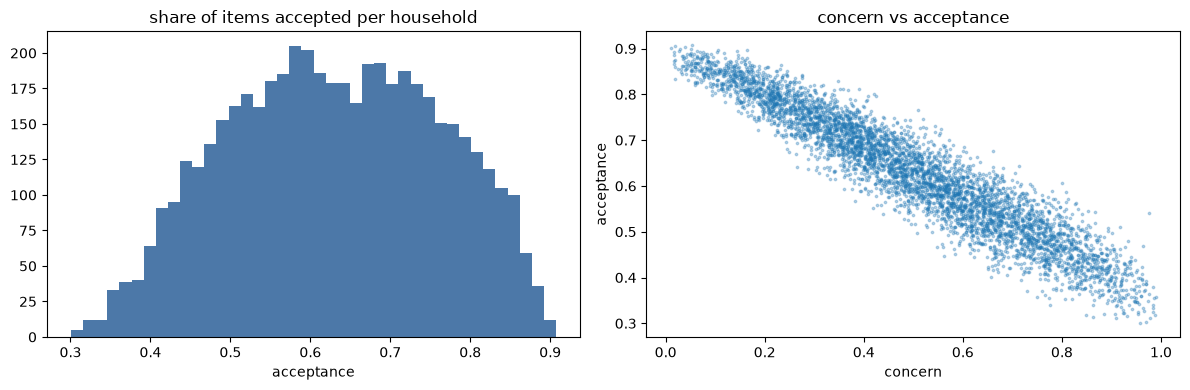

acceptance quantiles (0, 10, 50, 90, 100%): [0.3  0.45 0.63 0.81 0.91]


In [5]:
perm = V.mean(axis=1)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.hist(perm, bins=40, color="#4c78a8"); a.set_title("share of items accepted per household"); a.set_xlabel("acceptance")
b.scatter(H.concern, perm, s=3, alpha=0.3); b.set_xlabel("concern"); b.set_ylabel("acceptance"); b.set_title("concern vs acceptance")
plt.tight_layout(); plt.show()
print("acceptance quantiles (0, 10, 50, 90, 100%):", np.quantile(perm, [0, .1, .5, .9, 1]).round(2))

In [6]:
# Traits are correlated on purpose (config: trait_correlation).
H[TRAITS].corr().round(2)

,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation
concern,1.00,-0.39,0.48,0.50,0.39,-0.33
vendor_trust,-0.39,1.00,0.01,0.01,0.02,0.01
third_party_aversion,0.48,0.01,1.00,0.29,-0.00,-0.02
inference_aversion,0.50,0.01,0.29,1.00,0.01,-0.01
retention_sensitivity,0.39,0.02,-0.00,0.01,1.00,-0.03
benefit_orientation,-0.33,0.01,-0.02,-0.01,-0.03,1.00


## Answers to the candidate questions

In [7]:
bank = pd.DataFrame(question_bank()).set_index("id")
dist = {q: answers[q].value_counts(normalize=True).round(2).to_dict() for q in bank.index}
pd.DataFrame({"question": bank.text, "answers": pd.Series(dist)})

,question,answers
children,"Do children live in your home, or visit often?","{'no': 0.65, 'yes': 0.35}"
concern,How much do you worry about what smart devices...,"{'3': 0.34, '2': 0.26, '4': 0.26, '5': 0.07, '..."
trust_maker,How much do you trust device makers with your ...,"{'4': 0.36, '3': 0.34, '2': 0.16, '5': 0.11, '..."
data_content,"Video, photos and sound: may it leave your home?","{'ask': 0.45, 'never': 0.42, 'fine': 0.13}"
data_location,Where you are: may it leave your home?,"{'ask': 0.51, 'never': 0.32, 'fine': 0.18}"
data_identity,"Who you are (accounts, names, profile): may it...","{'ask': 0.53, 'fine': 0.31, 'never': 0.17}"
data_sensor,"Sensor readings (temperature, motion, …): may ...","{'fine': 0.58, 'ask': 0.37, 'never': 0.05}"
data_usage,How you use the device: may it leave your home?,"{'fine': 0.64, 'ask': 0.33, 'never': 0.03}"
data_network,Device and network details: may it leave your ...,"{'fine': 0.83, 'ask': 0.16, 'never': 0.01}"
purpose_core,May companies use your data for: making a feat...,"{'fine': 0.8, 'ask': 0.2, 'never': 0.0}"


In [8]:
# Answers should track the latent traits (that is what the decision tree will learn from).
codes = {"never": 0, "ask": 1, "fine": 2, "features": 2, "ok": 2, "briefly": 0, "any": 2, "no": 0, "yes": 1}
num = answers.drop(columns="household_id").apply(lambda c: pd.to_numeric(c.map(lambda v: codes.get(v, v)), errors="coerce"))
num.corrwith(pd.Series(perm)).sort_values().round(2).rename("correlation with household acceptance")

concern             -0.80
children            -0.05
retention            0.20
sharing              0.33
trust_maker          0.37
purpose_ads          0.37
data_network         0.39
inference            0.41
purpose_core         0.46
data_usage           0.49
purpose_analytics    0.51
data_sensor          0.51
purpose_comms        0.52
purpose_diag         0.53
purpose_personal     0.55
data_location        0.63
data_content         0.64
data_identity        0.65
Name: correlation with household acceptance, dtype: float64

## Save

Writes `data/` (gitignored) and refreshes `data/sample/` (committed). See `data/DATACARD.md`.

In [9]:
summary = dataset.save(DATA, items, synth, answers, cfg)
print(summary["decisions_sha256"])
print((DATA / "DATACARD.md").read_text()[:600], "...")

6560c4fb258e6581381db5f3961957c6ea90eb360be114a0f300986193e5e0a0
# Data card: synthetic PPD household preferences

Generated 2026-10-23 by `notebooks/02_generate_households.ipynb` with `config/generator.yaml`
(seed 20261023). Same config and seed reproduce the same data (decisions SHA-256 below).

## What it is

5,000 synthetic households and their decision on each of the 6,272 core PPD dataflows
(data type x purpose x action x source x handling context, draft-dsmullen-ppd-taxonomy-05 section 6), plus their
answers to the candidate onboarding questions.

**This is not survey data.** Every decision follows from latent traits and weights we chose; the directi ...
